# Exploring the deliveries table

A first look at `data/processed/deliveries.parquet`: how much of it carries wagon-wheel tracking, how scoring changes by phase, and how much a batter's scoring directions depend on the ball being bowled.

Build the table first with `uv run python scripts/build_dataset.py`.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from virtual_captain.paths import PROCESSED_DIR
from virtual_captain.viz import style
from virtual_captain.viz.wagon import plot_run_rose, run_shares, scoring_shots

style.apply()
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)
pl.Config.set_tbl_rows(30)

df = pl.scan_parquet(PROCESSED_DIR / "deliveries.parquet")
men = df.filter(pl.col("gender") == "male")
df.select(pl.len()).collect().item(), len(df.collect_schema())

(5850901, 75)

## Tracking coverage

Share of legal deliveries that carry each tracking field.

In [2]:
from virtual_captain.data.build import coverage_table

coverage_table(df.collect())

gender,format,era,balls,wagon,line,length,shot,control
str,str,str,u32,f64,f64,f64,f64,f64
"""male""","""ODI""","""2001-13""",619795,0.718,0.000,0.000,0.944,0.943
"""male""","""ODI""","""2014-19""",341347,0.780,0.806,0.806,0.873,0.873
"""male""","""ODI""","""2020+""",374964,0.668,0.770,0.770,0.770,0.770
"""male""","""T20""","""2001-13""",190410,0.667,0.005,0.005,0.782,0.544
"""male""","""T20""","""2014-19""",362955,0.549,0.591,0.591,0.619,0.621
"""male""","""T20""","""2020+""",1091674,0.526,0.611,0.611,0.608,0.611
"""male""","""TEST""","""2001-13""",763685,0.654,0.000,0.000,0.972,0.969
"""male""","""TEST""","""2014-19""",503533,0.774,0.954,0.954,1.000,0.998
"""male""","""TEST""","""2020+""",440649,0.767,0.995,0.995,0.997,0.995


## Scoring and wickets by phase

Runs and striker dismissals per legal ball. Test phases follow the age of the ball.

In [3]:
men.filter(pl.col("is_legal")).group_by("format", "phase").agg(
    pl.len().alias("balls"),
    pl.col("total_runs").mean().alias("runs_per_ball"),
    pl.col("striker_out").mean().alias("dismissals_per_ball"),
    (pl.col("is_four") | pl.col("is_six")).mean().alias("boundary_rate"),
).sort("format", "phase").collect()

format,phase,balls,runs_per_ball,dismissals_per_ball,boundary_rate
str,str,u32,f64,f64,f64
"""ODI""","""death""",187194,1.156,0.053,0.122
"""ODI""","""middle""",843656,0.793,0.023,0.075
"""ODI""","""powerplay""",305256,0.745,0.023,0.107
"""T20""","""death""",349116,1.494,0.086,0.182
"""T20""","""middle""",767027,1.205,0.047,0.126
"""T20""","""powerplay""",528896,1.214,0.045,0.181
"""TEST""","""new_ball""",571271,0.532,0.017,0.068
"""TEST""","""old_ball""",1136596,0.538,0.016,0.063


## Length decides the side of the wicket

Share of runs scored on the off side (wagon angle 180-360, left-handers mirrored) for each length. Short balls get pulled and hooked; full balls get driven.

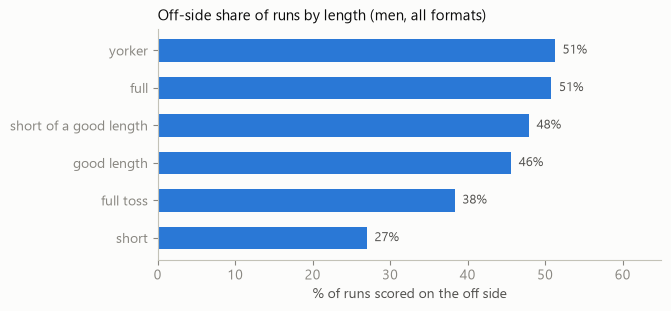

ball_length,off_side_share,shots
str,f64,u32
"""short""",0.270,70786
"""full toss""",0.383,38668
"""good length""",0.456,443917
"""short of a good length""",0.479,239556
"""full""",0.508,256078
"""yorker""",0.512,13801


In [4]:
shots = scoring_shots(men.collect())
off = pl.col("wagon_angle") >= 180
off_share = pl.col("runs_off_bat").filter(off).sum() / pl.col("runs_off_bat").sum()

by_length = (
    shots.filter(pl.col("ball_length").is_not_null())
    .group_by("ball_length")
    .agg(off_share.alias("off_side_share"), pl.len().alias("shots"))
    .sort("off_side_share")
)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(
    by_length["ball_length"], by_length["off_side_share"] * 100, color=style.SERIES[0], height=0.6
)
for y, v in enumerate(by_length["off_side_share"]):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color=style.INK_SECONDARY)
ax.set_xlim(0, 65)
ax.set_xlabel("% of runs scored on the off side")
ax.set_title("Off-side share of runs by length (men, all formats)", loc="left")
plt.show()
by_length

## Which way the spinner turns it

Off-side share of runs against spin, split by whether the stock ball turns into the batter (off-spin to a right-hander) or away (leg-spin or left-arm orthodox to a right-hander).

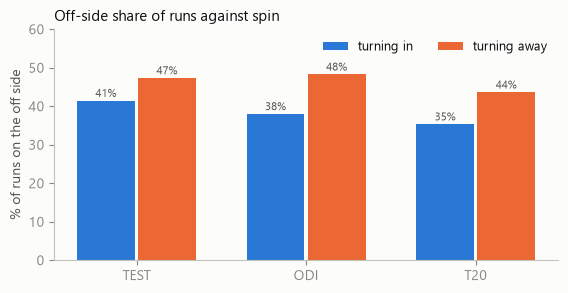

format,spin_turn,off_side_share,shots
str,str,f64,u32
"""ODI""","""away""",0.483,118004
"""ODI""","""in""",0.380,99684
"""T20""","""away""",0.436,151333
"""T20""","""in""",0.353,99677
"""TEST""","""away""",0.473,98320
"""TEST""","""in""",0.414,92194


In [5]:
by_turn = (
    shots.filter(pl.col("spin_turn").is_not_null())
    .group_by("format", "spin_turn")
    .agg(off_share.alias("off_side_share"), pl.len().alias("shots"))
    .sort("format", "spin_turn")
)
formats = ["TEST", "ODI", "T20"]
fig, ax = plt.subplots(figsize=(6.5, 3))
for i, (turn, colour) in enumerate([("in", style.SERIES[0]), ("away", style.SERIES[1])]):
    vals = [
        by_turn.filter((pl.col("format") == f) & (pl.col("spin_turn") == turn))[
            "off_side_share"
        ].item()
        * 100
        for f in formats
    ]
    xs = [j + (i - 0.5) * 0.36 for j in range(3)]
    ax.bar(xs, vals, width=0.34, color=colour, label=f"turning {turn}")
    for x, v in zip(xs, vals, strict=True):
        ax.text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=style.INK_SECONDARY)
ax.set_xticks(range(3), formats)
ax.set_ylim(0, 60)
ax.set_ylabel("% of runs on the off side")
ax.set_title("Off-side share of runs against spin", loc="left")
ax.legend(loc="upper right", ncol=2, fontsize=9)
plt.show()
by_turn

## One batter, two contexts

Steve Smith's scoring zones against pace and against spin, on the same scale.

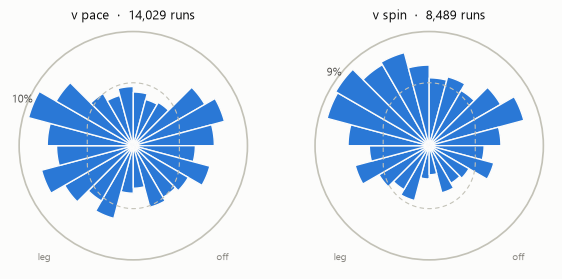

In [6]:
smith = shots.filter(pl.col("striker") == "SPD Smith")
parts = {k: smith.filter(pl.col("pace_or_spin") == k) for k in ("pace", "spin")}
top = max(run_shares(p).max() for p in parts.values())
fig, axes = plt.subplots(1, 2, figsize=(7, 3.8))
for ax, (k, p) in zip(axes, parts.items(), strict=True):
    plot_run_rose(ax, p, top, title=f"v {k}  ·  {p['runs_off_bat'].sum():,} runs")
plt.show()